# **1. BARRIOS**

**Objetivo:** crear la tabla base del proyecto: los 73 barrios oficiales de Barcelona con su código, nombre, distrito, superficie y contorno. Todos los demás cuadernos se unirán a esta tabla mediante `codi_barri`.

**Entradas** (en `data/raw`):
- `barcelona_barris_wgs84.geojson`: límites de los 73 barrios.
- `barcelona_districtes_wgs84.geojson`: límites de los 10 distritos.

**Fuente y año:** Open Data BCN (Ajuntament de Barcelona), descarga de 2026.

**Salidas** (en `data/processed`):
- `barrios_base.gpkg` (barrios con su mapa) y `distritos_base.gpkg`.
- `barrios_base.csv`: una fila por barrio con `codi_barri`, `nom_barri`, `codi_districte`, `nom_districte` y `area_km2`.

**Sistema de coordenadas:** ETRS89 / UTM 31N (EPSG:25831), en metros.

**Limitaciones:** los límites son administrativos e incluyen bosque (Collserola), puerto y playas. Un barrio grande no es necesariamente un barrio muy urbano.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

import os
os.makedirs(PROCESSED, exist_ok=True)

Mounted at /content/drive


 Cargamos las librerías: **pandas** trabaja con tablas, **geopandas** es pandas con mapas y **matplotlib** dibuja gráficos.

In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)    # que pandas enseñe todas las columnas

### 1. Cargar los datos
Son dos archivos GeoJSON: los 73 barrios y los 10 distritos.

In [4]:
barrios = gpd.read_file(RAW + 'barcelona_barris_wgs84.geojson')
distritos = gpd.read_file(RAW + 'barcelona_districtes_wgs84.geojson')

print('Barrios:', barrios.shape, '| Distritos:', distritos.shape)

Barrios: (73, 36) | Distritos: (10, 36)


## 2. Inspección de los datos

### 2.1 Primeras filas

In [5]:
display(barrios.head(3))

,FID,ID_ANNEX,ANNEXDESCR,ID_TEMA,TEMA_DESCR,ID_CONJUNT,CONJ_DESCR,ID_SUBCONJ,SCONJ_DESC,ID_ELEMENT,ELEM_DESCR,NIVELL,NDESCR_CA,NDESCR_ES,NDESCR_EN,TERME,DISTRICTE,BARRI,AEB,SEC_CENS,GRANBARRI,ZUA,AREA_I,LITERAL,PERIMETRE,AREA,CODI_UA,TIPUS_UA,NOM,WEB1,WEB2,WEB3,FHEX_COLOR,Shape_Leng,Shape_Area,geometry
0,11,01,Grup - I,0104,Unitats Administratives,010413,Barris,01041301,Barri,0104130101,Límit de barri,ADM_03_PL,Límit de barri (polígon),Límite de barrrio (polígono),Neighborhood boundary (polygon),080193,01,01,-,-,01,-,-,01,5521.647,1100286.137,01,BARRI,el Raval,http://lameva.barcelona.cat/ciutatvella/ca/hom...,http://www.bcn.cat/estadistica/catala/dades/in...,http://www.bcn.cat/estadistica/catala/document...,#E66900,5521.646549,1.100286e+06,"POLYGON ((2.16471 41.38593, 2.16401 41.3854, 2..."
1,12,01,Grup - I,0104,Unitats Administratives,010413,Barris,01041301,Barri,0104130101,Límit de barri,ADM_03_PL,Límit de barri (polígon),Límite de barrrio (polígono),Neighborhood boundary (polygon),080193,01,02,-,-,02,-,-,02,5198.000,815593.938,02,BARRI,el Barri Gòtic,http://lameva.barcelona.cat/ciutatvella/ca/hom...,http://www.bcn.cat/estadistica/catala/dades/in...,http://www.bcn.cat/estadistica/catala/document...,#E66900,5197.999887,8.155939e+05,"POLYGON ((2.17701 41.38525, 2.17658 41.38558, ..."
2,13,01,Grup - I,0104,Unitats Administratives,010413,Barris,01041301,Barri,0104130101,Límit de barri,ADM_03_PL,Límit de barri (polígon),Límite de barrrio (polígono),Neighborhood boundary (polygon),080193,01,03,-,-,03,-,-,03,13853.129,1179381.956,03,BARRI,la Barceloneta,http://lameva.barcelona.cat/ciutatvella/ca/hom...,http://www.bcn.cat/estadistica/catala/dades/in...,http://www.bcn.cat/estadistica/catala/document...,#E66900,13853.129525,1.179382e+06,"POLYGON ((2.19623 41.38745, 2.19617 41.38746, ..."


### 2.2 ¿Qué columnas aportan información?

In [6]:
n_valores = barrios.drop(columns='geometry').nunique()

print('Columnas con un solo valor (no aportan nada):')
print(n_valores[n_valores == 1].index.tolist())
print()
print('Columnas con varios valores (las miramos):')
print(n_valores[n_valores > 1].index.tolist())

Columnas con un solo valor (no aportan nada):
['ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'AEB', 'SEC_CENS', 'ZUA', 'AREA_I', 'TIPUS_UA', 'FHEX_COLOR']

Columnas con varios valores (las miramos):
['FID', 'DISTRICTE', 'BARRI', 'GRANBARRI', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'Shape_Leng', 'Shape_Area']


**Qué mirar:** de todas, las importantes son:
- `BARRI`: el **código** del barrio.
- `NOM`: el **nombre**.
- `DISTRICTE`: el código del distrito al que pertenece.
- `AREA`: la superficie oficial en m².
- `geometry`: el contorno de cada barrio.

El resto (enlaces web, colores, etc.) las ignoramos.

### 2.3 Tipos de datos, vacíos y duplicados

In [7]:
barrios[['BARRI', 'NOM', 'DISTRICTE', 'AREA']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   BARRI      73 non-null     object 
 1   NOM        73 non-null     object 
 2   DISTRICTE  73 non-null     object 
 3   AREA       73 non-null     float64
dtypes: float64(1), object(3)
memory usage: 2.4+ KB


In [8]:
print('Códigos de barrio repetidos:', barrios['BARRI'].duplicated().sum())
print('Valores vacíos en BARRI, NOM y AREA:', barrios[['BARRI', 'NOM', 'AREA']].isna().sum().tolist())
display(barrios[['BARRI', 'NOM', 'DISTRICTE', 'AREA']].head(8))

Códigos de barrio repetidos: 0
Valores vacíos en BARRI, NOM y AREA: [0, 0, 0]


,BARRI,NOM,DISTRICTE,AREA
0,01,el Raval,01,1100286.137
1,02,el Barri Gòtic,01,815593.938
2,03,la Barceloneta,01,1179381.956
3,04,"Sant Pere, Santa Caterina i la Ribera",01,1109668.777
4,05,el Fort Pienc,02,929355.787
5,06,la Sagrada Família,02,1041829.343
6,07,la Dreta de l'Eixample,02,2119874.214
7,08,l'Antiga Esquerra de l'Eixample,02,1228435.836


### 2.4 Resumen de la superficie

In [9]:
display(barrios['AREA'].describe().round(0))
print('Barrio más pequeño:', barrios.loc[barrios['AREA'].idxmin(), 'NOM'])
print('Barrio más grande:', barrios.loc[barrios['AREA'].idxmax(), 'NOM'])

,AREA
count,73.0
mean,1393180.0
std,2082980.0
min,118685.0
25%,591219.0
50%,924840.0
75%,1321188.0
max,14237476.0


Barrio más pequeño: Can Peguera
Barrio más grande: la Marina del Prat Vermell


##2.5 Comprobaciones de mapa

In [10]:
print('Sistema de coordenadas:', barrios.crs)
print()
print('Tipo de forma:')
print(barrios.geom_type.value_counts())
print()
print('Formas válidas (True) y no válidas (False):')
print(barrios.is_valid.value_counts())
print()
print('Extensión (xmin, ymin, xmax, ymax):', barrios.total_bounds)

Sistema de coordenadas: EPSG:4326

Tipo de forma:
Polygon         71
MultiPolygon     2
Name: count, dtype: int64

Formas válidas (True) y no válidas (False):
True    73
Name: count, dtype: int64

Extensión (xmin, ymin, xmax, ymax): [ 2.05233291 41.31703852  2.228045   41.46829759]



### 2.6 Visión del mapa

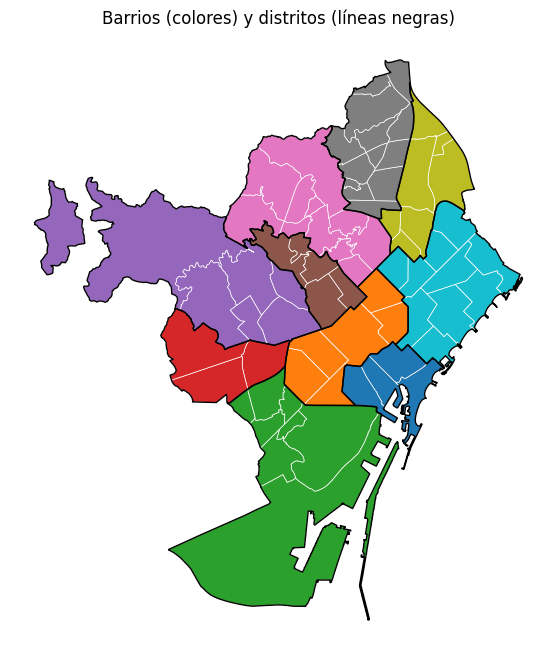

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
barrios.plot(ax=ax, column='DISTRICTE', cmap='tab10', edgecolor='white', linewidth=0.5)
distritos.boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_axis_off()
plt.title('Barrios (colores) y distritos (líneas negras)')
plt.show()

## 3. Limpieza

### 3.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros

In [12]:
base = barrios[['BARRI', 'NOM', 'DISTRICTE', 'AREA', 'geometry']].copy()

base = base.rename(columns={
    'BARRI': 'codi_barri',
    'NOM': 'nom_barri',
    'DISTRICTE': 'codi_districte',
    'AREA': 'area_oficial_m2',
})
display(base.head(3))

,codi_barri,nom_barri,codi_districte,area_oficial_m2,geometry
0,01,el Raval,01,1100286.137,"POLYGON ((2.16471 41.38593, 2.16401 41.3854, 2..."
1,02,el Barri Gòtic,01,815593.938,"POLYGON ((2.17701 41.38525, 2.17658 41.38558, ..."
2,03,la Barceloneta,01,1179381.956,"POLYGON ((2.19623 41.38745, 2.19617 41.38746, ..."


### 3.2 Convertimos los códigos de texto a número

Pasamos `'01'` a `1`. Así coincidirá con los otros archivos del proyecto.

In [13]:
base['codi_barri'] = base['codi_barri'].astype(int)
base['codi_districte'] = base['codi_districte'].astype(int)

print(base[['codi_barri', 'codi_districte']].dtypes)
print(base['codi_barri'].head(3).tolist())

codi_barri        int64
codi_districte    int64
dtype: object
[1, 2, 3]


### 3.3 Añadimos el nombre de cada distrito

Los nombres de distrito están en el otro archivo. Los traemos con un `merge`

In [14]:
nombres_distrito = distritos[['DISTRICTE', 'NOM']].copy()
nombres_distrito['codi_districte'] = nombres_distrito['DISTRICTE'].astype(int)
nombres_distrito = nombres_distrito.rename(columns={'NOM': 'nom_districte'})
nombres_distrito = nombres_distrito[['codi_districte', 'nom_districte']]

base = base.merge(nombres_distrito, on='codi_districte', how='left')

print('Barrios sin nombre de distrito:', base['nom_districte'].isna().sum())
display(base[['codi_barri', 'nom_barri', 'codi_districte', 'nom_districte']].head(6))

Barrios sin nombre de distrito: 0


,codi_barri,nom_barri,codi_districte,nom_districte
0,1,el Raval,1,Ciutat Vella
1,2,el Barri Gòtic,1,Ciutat Vella
2,3,la Barceloneta,1,Ciutat Vella
3,4,"Sant Pere, Santa Caterina i la Ribera",1,Ciutat Vella
4,5,el Fort Pienc,2,Eixample
5,6,la Sagrada Família,2,Eixample


### 3.4 Pasamos el mapa a metros y calculamos la superficie

Cambiamos el sistema de coordenadas de grados (`EPSG:4326`) a **metros** (`EPSG:25831`, el habitual en Cataluña). Todos los demás archivos del proyecto usarán este mismo sistema.

Después calculamos la superficie de cada barrio a partir del dibujo y la comparamos con la que da el archivo oficial.

In [15]:
base = base.to_crs(epsg=25831)
distritos_m = distritos.to_crs(epsg=25831)

print('Unidad del mapa:', base.crs.axis_info[0].unit_name)

base['area_km2'] = base.geometry.area / 1_000_000
base['dif_area_pct'] = (base['area_km2'] * 1_000_000 - base['area_oficial_m2']) / base['area_oficial_m2'] * 100

print('Mayor diferencia con el área oficial (%):', round(base['dif_area_pct'].abs().max(), 2))

Unidad del mapa: metre
Mayor diferencia con el área oficial (%): 0.0


Una vez comprobado, esa columna ya no hace falta

In [16]:
base = base.drop(columns=['dif_area_pct', 'area_oficial_m2'])
display(base.drop(columns='geometry').head(3).round(3))

,codi_barri,nom_barri,codi_districte,nom_districte,area_km2
0,1,el Raval,1,Ciutat Vella,1.100
1,2,el Barri Gòtic,1,Ciutat Vella,0.816
2,3,la Barceloneta,1,Ciutat Vella,1.179


### 3.5 Mapa interactivo de los barrios

Representamos el mapa interactivo utilizando los datos ya limpios en `base`, coloreando por distrito y mostrando el nombre del barrio, distrito y su superficie calculada en km².

In [17]:
# Copia solo para el mapa: redondeamos aquí y NO en 'base', para que 'base' conserve el área exacta
mapa_barrios = base.copy()
mapa_barrios['area_km2'] = mapa_barrios['area_km2'].round(2)

mapa_barrios.explore(
    column="nom_districte",
    tooltip=["nom_barri", "codi_barri", "nom_districte", "area_km2"],
    popup=True,
    tiles=None,
    legend=True,
    cmap="tab10"
)

## 4. Comprobaciones finales

In [18]:
print('Barrios:', len(base), '(esperado 73)')
print('Códigos del 1 al 73 completos:', sorted(base['codi_barri']) == list(range(1, 74)))
print('Superficie total (km2):', round(base['area_km2'].sum(), 1), '(esperado 101,7)')
print()
print('Barrios por distrito:')
print(base.groupby('nom_districte')['codi_barri'].count())

Barrios: 73 (esperado 73)
Códigos del 1 al 73 completos: True
Superficie total (km2): 101.7 (esperado 101,7)

Barrios por distrito:
nom_districte
Ciutat Vella            4
Eixample                6
Gràcia                  5
Horta-Guinardó         11
Les Corts               3
Nou Barris             13
Sant Andreu             7
Sant Martí             10
Sants-Montjuïc          8
Sarrià-Sant Gervasi     6
Name: codi_barri, dtype: int64


## 5. Guardamos la base

Guardamos tres archivos en `data/processed`: los barrios con su mapa, los distritos, y una versión sin mapa en CSV.

In [19]:
base.to_file(PROCESSED + 'barrios_base.gpkg', driver='GPKG', layer='barrios')
distritos_m[['DISTRICTE', 'NOM', 'geometry']].to_file(PROCESSED + 'distritos_base.gpkg', driver='GPKG', layer='distritos')
base.drop(columns='geometry').to_csv(PROCESSED + 'barrios_base.csv', index=False, encoding='utf-8-sig')

print('Guardado correctamente en la ruta:', PROCESSED)
print('Formato final:', base.shape)

Guardado correctamente en la ruta: /content/drive/MyDrive/proyectofinal_ITAcademy/data/processed/
Formato final: (73, 6)
